Tomasz Lepszy, *475898*

*Synthetic Data Generation with Diffusion Models*

# 0. Exploring the data and the methods

## Introduction

This notebook trains no classifier and generates no image. Its job is to look before experimenting: at the eight-breed Oxford-IIIT Pet subset, at how the breeds differ and overlap, at what the 15 Egyptian Mau training photos actually show, at how the data is split, and at how the classifier and the diffusion tools work. Later meetings interpret their results against what is found here.

In [52]:
# Workspace setup

import os
from pathlib import Path

here = Path.cwd()
os.chdir(next(p for p in [here, *here.parents] if (p / "pyproject.toml").exists()))

from torchvision.datasets import OxfordIIITPet

for part in ("trainval", "test"):
    OxfordIIITPet(root="./data", split=part, download=True)

from synthdata.data import image_path, load_split, trimap_path

course_split = load_split()
missing = [p.image for p in course_split
           if not (image_path(p.image).exists() and trimap_path(p.image).exists())]
assert not missing, f"{len(missing)} photos missing from ./data, e.g. {missing[0]}"

ROOT = Path(".")

print("Workspace Status")
print(f"  • Repository : {Path.cwd().name}")
print(f"  • Data dir   : ./data")
print(f"  • Verified   : {len(course_split):,} course photos + trimap masks")


Workspace Status
  • Repository : dane_syntetyczne
  • Data dir   : ./data
  • Verified   : 905 course photos + trimap masks


## 1. The question and the arc of the course

> **Can images made by diffusion models improve recognition of Egyptian Mau, an under-represented cat breed, without harming the other seven breeds?**

Everything is fixed except one thing: **where the 55 extra Egyptian Mau training examples come from**. The five meetings walk along one axis, from "the added image *is* a real photo" to "the added image is invented from words":

| Meeting | Source of the 55 extra Mau examples | What is kept from the real photos | What is new |
| --- | --- | --- | --- |
| 1 | copies (`oversample`), transformed copies (`augment`) | everything | nothing / geometry and lighting |
| 2 | **text-to-image** from a prompt (SD 1.5, SDXL-Turbo) | nothing | everything |
| 3 | **img2img** and **IP-Adapter**, starting from the 15 photos | layout and colours / the cat's look | details, pose, background |
| 4 | **inpainting** (new background) and **outpainting** (zoom out) | the cat's own pixels | the surroundings |
| 5 | final comparison of the chosen runs on the test photos | — | — |

Two things make Egyptian Mau hard, and the exercises are built to separate them: it has **4.7× fewer training photos** than any other breed, and it **looks like several of them**. Section 2 looks at how true the second part is.

In [53]:
# Experiment configuration

import json
import random
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import torch
from PIL import Image

%config InlineBackend.figure_formats = ['jpeg']  # photo grids as JPEG keep the notebook small
plt.rcParams["figure.dpi"] = 72

from synthdata import balance, config, data, inputs, pools  # noqa: E402
from synthdata import train as T  # noqa: E402

CLASSES, TARGET = config.CLASSES, config.TARGET
split = pd.read_csv(data.SPLIT_CSV)
rng = np.random.default_rng(0)

print("Experiment Configuration")
print(f"  • Breeds ({len(CLASSES)}) : {', '.join(CLASSES)}")
print(f"  • Target class  : {TARGET} (+{config.BUDGET} synthetic budget)")
print(f"  • Random seeds  : {', '.join(map(str, config.SEEDS))}")

Experiment Configuration
  • Breeds (8) : Abyssinian, Bengal, Birman, Bombay, Egyptian Mau, Ragdoll, Russian Blue, Siamese
  • Target class  : Egyptian Mau (+55 synthetic budget)
  • Random seeds  : 0, 1, 2, 3, 4


## 2. The dataset

### 2.1 Breeds and split

[Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) has 37 breeds of cats and dogs with about 200 photos each, collected from the web (Catster, Dogster, Flickr) and labelled by breed. Every photo also has a head bounding box and a pixel-level **trimap** (pet / background / border). The course keeps 8 of the 12 cat breeds and fixes the split in `data/split.csv`.

The imbalance is artificial: the original dataset has about 200 Egyptian Mau photos; the split keeps 15 for training.

In [54]:
# The dataset in numbers

counts = pd.crosstab(split["breed"], split["role"]).reindex(index=CLASSES, columns=["train", "val", "test"])
counts["Total"] = counts.sum(axis=1)
counts["Train Share"] = counts["train"] / counts["train"].sum()
counts.loc["All Breeds"] = counts.sum()

counts = counts.rename(columns={
    "train": "Training Set",
    "val": "Validation Set",
    "test": "Test Set",
    "Total": "Total Photos",
    "Train Share": "Share of Training Set",
})
counts.index.name = "Cat Breed"
counts.columns.name = None  # removes the extra 'role' label above the columns

(
    counts.style
    .format({
        "Training Set": "{:,.0f}",
        "Validation Set": "{:,.0f}",
        "Test Set": "{:,.0f}",
        "Total Photos": "{:,.0f}",
        "Share of Training Set": "{:.1%}",
    })
    .set_table_styles([
        {"selector": "th.col_heading", "props": [("background-color", "#f4f6f8"), ("color", "#1f2937"), ("font-weight", "bold"), ("border-bottom", "2px solid #cbd5e1"), ("padding", "8px 12px")]},
        {"selector": "th.index_name", "props": [("background-color", "#f4f6f8"), ("color", "#1f2937"), ("font-weight", "bold"), ("border-bottom", "2px solid #cbd5e1"), ("padding", "8px 12px")]},
        {"selector": "td, th.row_heading", "props": [("padding", "6px 12px")]},
    ])
    .apply(lambda row: ["background-color: #fff3cd; font-weight: bold" if row.name == TARGET else "" for _ in row], axis=1)
    .apply(lambda row: ["border-top: 2px solid #888; font-weight: bold" if row.name == "All Breeds" else "" for _ in row], axis=1)
)

,Training Set,Validation Set,Test Set,Total Photos,Share of Training Set
Cat Breed,,,,,
Abyssinian,70,20,30,120,13.9%
Bengal,70,20,30,120,13.9%
Birman,70,20,30,120,13.9%
Bombay,70,20,30,120,13.9%
Egyptian Mau,15,20,30,65,3.0%
Ragdoll,70,20,30,120,13.9%
Russian Blue,70,20,30,120,13.9%
Siamese,70,20,30,120,13.9%
All Breeds,505,160,240,905,100.0%


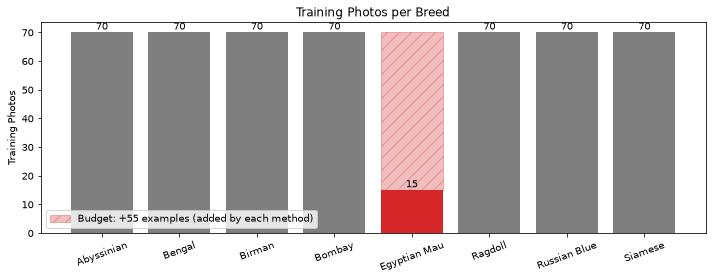

In [55]:
# Training Photos per Breed

fig, ax = plt.subplots(figsize=(10, 4))
train = counts.loc[CLASSES, "Training Set"].astype(int)

ax.bar(CLASSES, train, color=["tab:red" if b == TARGET else "tab:gray" for b in CLASSES])
ax.bar(TARGET, config.BUDGET, bottom=train[TARGET], color="tab:red", alpha=0.3, hatch="//",
       edgecolor="tab:red", label=f"Budget: +{config.BUDGET} examples (added by each method)")

for i, v in enumerate(train):
    ax.text(i, v + 1, str(v), ha="center")

ax.set_ylabel("Training Photos")
ax.set_title("Training Photos per Breed")
ax.tick_params(axis="x", rotation=20)
ax.legend()
fig.tight_layout()
plt.show()

### 2.2 Size, aspect ratio and framing

Because these are scraped web photos of pets, they come from all kinds of cameras, distances, and aspect ratios—and neither model sees the original frame intact. The **classifier** shrinks the short side to 256 px and takes a **224×224** crop, while the **diffusion pipeline** forces everything into a **512×512** centre-crop. Before looking at the cats themselves, we want to probe two structural properties that could quietly skew training or generation:

1. **Resolution and aspect ratio:** How often are images upscaled, downscaled, or heavily sliced at the edges when forced into a square?
2. **Pet share (measured from the trimap):** What fraction of the frame is actually cat versus background? This acts as a quick proxy for framing—distinguishing tight facial close-ups (high pet share) from wide environmental shots where a small cat sits on a lawn (low pet share), which may behave very differently under cropping and inpainting.

In [56]:
# Measure image dimensions, orientation, and trimap pet share across all breeds.
rows = []
for row in split.itertuples():
    with Image.open(data.image_path(str(row.image))) as im:
        w, h = im.size
    rows.append({
        "image": row.image,
        "breed": row.breed,
        "role": row.role,
        "width": w,
        "height": h,
        "orientation": "landscape" if w > h else ("portrait" if h > w else "square"),
        "pet_share": inputs.pet_share(str(row.image)),
    })

photos_df = pd.DataFrame(rows)
photos_df["short_side"] = photos_df[["width", "height"]].min(axis=1)

summary = (
    photos_df.groupby("breed")
    .agg(
        photos=("image", "count"),
        median_short_side=("short_side", "median"),
        landscape=("orientation", lambda s: (s == "landscape").mean()),
        pet_share_median=("pet_share", "median"),
        pet_share_min=("pet_share", "min"),
        pet_share_max=("pet_share", "max"),
    )
    .reindex(CLASSES)
)

display_summary = summary.rename(columns={
    "photos": "Total Photos",
    "median_short_side": "Median Short Side (px)",
    "landscape": "Landscape Share",
    "pet_share_median": "Median Pet Share",
    "pet_share_min": "Min Pet Share",
    "pet_share_max": "Max Pet Share",
})
display_summary.index.name = "Cat Breed"

(
    display_summary.style
    .format({
        "Total Photos": "{:,.0f}",
        "Median Short Side (px)": "{:,.0f} px",
        "Landscape Share": "{:.0%}",
        "Median Pet Share": "{:.1%}",
        "Min Pet Share": "{:.1%}",
        "Max Pet Share": "{:.1%}",
    })
    .set_table_styles([
        {"selector": "th.col_heading", "props": [("background-color", "#f4f6f8"), ("color", "#1f2937"), ("font-weight", "bold"), ("border-bottom", "2px solid #cbd5e1"), ("padding", "8px 12px")]},
        {"selector": "th.index_name", "props": [("background-color", "#f4f6f8"), ("color", "#1f2937"), ("font-weight", "bold"), ("border-bottom", "2px solid #cbd5e1"), ("padding", "8px 12px")]},
        {"selector": "td, th.row_heading", "props": [("padding", "6px 12px")]},
    ])
    .apply(lambda row: ["background-color: #fff3cd; font-weight: bold" if row.name == TARGET else "" for _ in row], axis=1)
)

,Total Photos,Median Short Side (px),Landscape Share,Median Pet Share,Min Pet Share,Max Pet Share
Cat Breed,,,,,,
Abyssinian,120,333 px,62%,24.0%,5.2%,77.3%
Bengal,120,332 px,83%,24.0%,3.2%,68.8%
Birman,120,334 px,72%,34.6%,2.0%,80.7%
Bombay,120,314 px,70%,30.7%,4.7%,87.1%
Egyptian Mau,65,329 px,60%,22.4%,0.0%,67.8%
Ragdoll,120,364 px,68%,40.6%,4.9%,86.3%
Russian Blue,120,334 px,62%,26.6%,2.4%,82.6%
Siamese,120,375 px,67%,28.4%,4.0%,83.7%


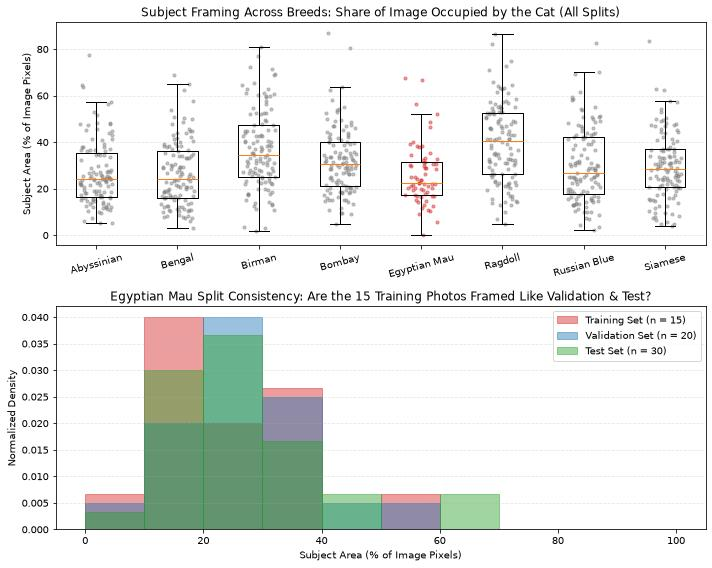

In [57]:
# Compare subject framing (pet share) across all breeds.
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Panel 1: Framing distribution across all eight breeds
ax = axes[0]
groups = [photos_df.loc[photos_df["breed"] == b, "pet_share"] * 100 for b in CLASSES]
ax.boxplot(groups, tick_labels=CLASSES, showfliers=False)

for i, g in enumerate(groups, start=1):
    ax.scatter(
        np.full(len(g), i) + rng.uniform(-0.2, 0.2, len(g)),
        g,
        s=10,
        alpha=0.45,
        color="tab:red" if CLASSES[i - 1] == TARGET else "tab:gray",
    )

ax.set_ylabel("Subject Area (% of Image Pixels)")
ax.set_title("Subject Framing Across Breeds: Share of Image Occupied by the Cat (All Splits)")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", linestyle="--", alpha=0.3)

# Panel 2: Split consistency within the target minority class
ax = axes[1]
mau = photos_df[photos_df["breed"] == TARGET]
role_labels = {"train": "Training Set", "val": "Validation Set", "test": "Test Set"}

for role, color in zip(["train", "val", "test"], ["tab:red", "tab:blue", "tab:green"]):
    g = mau.loc[mau["role"] == role, "pet_share"] * 100
    ax.hist(
        g,
        bins=np.linspace(0, 100, 11),
        alpha=0.45,
        color=color,
        edgecolor=color,
        label=f"{role_labels[role]} (n = {len(g)})",
        density=True,
    )

ax.set_xlabel("Subject Area (% of Image Pixels)")
ax.set_ylabel("Normalized Density")
ax.set_title("Egyptian Mau Split Consistency: Are the 15 Training Photos Framed Like Validation & Test?")
ax.legend(frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.3)

fig.tight_layout()
plt.show()

What the framing audit shows:

* **Resolution:** the median short side is 314–375 px for every breed, so the classifier (256 px short side) mostly *downscales*, while the diffusion pipeline (512 × 512) mostly *upscales*: generated images will be sharper than the source photos they start from.
* **Orientation:** 60–83% of photos are landscape (Bengal the most, 83%), so the square crops of both pipelines usually cut the sides of the frame.
* **Egyptian Mau is the most loosely framed breed:** median pet share 22.4%, the lowest of all eight (Ragdoll 40.6%, Birman 34.6%). The cat often fills less than a quarter of the photo, which leaves a lot of background for the classifier to look at and for inpainting to repaint.
* **Training vs validation/test framing is consistent:** all three Mau splits are concentrated at 10–40% pet share. Test has a slightly longer tail of close framings (up to 60–70%), and training contains one broken annotation at 0% (#165, see 2.7).

### 2.3 Eight breeds side by side

Numbers and bounding boxes only tell us how much of the frame a cat occupies—not whether the breed is actually recognizable after a square crop, or whether a breed is secretly correlated with a specific setting. Before letting a model train or generate from these images, we need to inspect the raw inputs directly.

Each row below shows eight random training photos per breed, centre-cropped to a square exactly as the diffusion pipelines see them. Scanning across rows highlights four visual factors that govern downstream performance:

* **Coat traits:** Colour, hair length, and markings (such as spots vs. rosettes) that carry genuine breed signal—and determine how easily breeds can be confused.
* **Framing:** Whether the square crop preserves diagnostic body proportions or reduces the image to a tight facial portrait.
* **Backgrounds:** Spurious context cues—indoor furniture, grass, or studio backdrops—that a classifier can exploit as shortcuts or a generator may accidentally copy.
* **Poses:** Recurring postures (lying, sitting, camera-facing) that show how visually diverse—or narrow—the available training examples actually are.

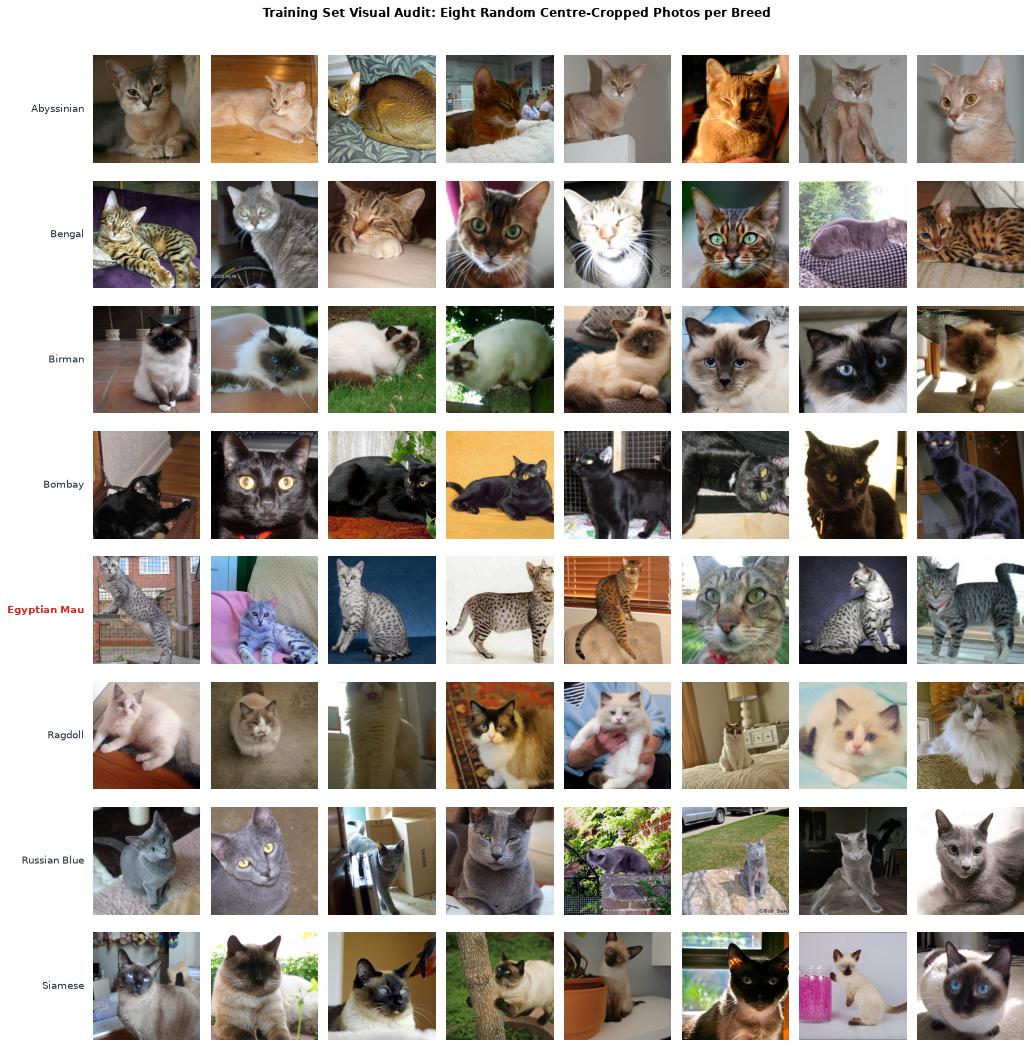

In [58]:
# Define reusable image grid helpers and display 8 square-cropped training samples per breed.
def show_grid(names, ncols, titles=None, row_labels=None, highlight_row=None,
              size=2.2, suptitle=None, loader=inputs.source_photo):
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    axes = np.atleast_2d(axes).reshape(nrows, ncols)

    for ax in axes.ravel():
        ax.axis("off")

    for k, name in enumerate(names):
        r, c = divmod(k, ncols)
        axes[r, c].imshow(loader(name))
        if titles is not None:
            axes[r, c].set_title(titles[k], fontsize=8)

    if row_labels is not None:
        for r, label in enumerate(row_labels):
            is_target = (label == highlight_row)
            axes[r, 0].text(
                -0.08, 0.5, label,
                transform=axes[r, 0].transAxes,
                ha="right", va="center",
                fontsize=10,
                fontweight="bold" if is_target else "normal",
                color="tab:red" if is_target else "#1f2937",
            )

    if suptitle:
        fig.suptitle(suptitle, fontsize=12, fontweight="bold", y=1.01)

    fig.tight_layout()
    plt.show()


def sample(breed, role, n):
    names = split.query("breed == @breed and role == @role")["image"].to_numpy()
    return list(rng.choice(names, min(n, len(names)), replace=False))


grid = [name for breed in CLASSES for name in sample(breed, "train", 8)]
show_grid(
    grid,
    ncols=8,
    row_labels=CLASSES,
    highlight_row=TARGET,
    size=1.8,
    suptitle="Training Set Visual Audit: Eight Random Centre-Cropped Photos per Breed",
)

Scanning the grid reveals a clear visual topology across the eight breeds—and tells us exactly where both the classifier and the synthetic generators are most likely to stumble:

* **Visually isolated breeds:** **Bombay** (solid black, short hair), **Siamese** (slim build, cream body, dark points, blue eyes), and the long-haired, colour-pointed pair **Birman** and **Ragdoll** sit far from *Egyptian Mau* in feature space. *(Birman and Ragdoll form their own confusable pair, but neither threatens the target class.)*
* **The *Egyptian Mau* neighbourhood:** Three breeds share key visual axes with the target class:
    * **Bengal** shares the spotted/marbled coat pattern, though on a warmer brown-gold ground.
    * **Abyssinian** matches the slim build, large ears, and ticked short fur, but in a uniform warm ruddy tone.
    * **Russian Blue** shares the cool silver-grey coat tone and green eyes, lacking only the spots.
* **Target signature (*Egyptian Mau*):** A short silver-to-bronze coat with random dark spots, striped legs and tail, green eyes, and a distinct forehead "M". Visually, it sits **between Russian Blue and Abyssinian in silhouette and colour**, and **next to Bengal in pattern**—meaning weak diffusion prompts or under-trained classifiers risk drifting into one of these three neighbours.

*We will test whether the classifier's actual feature space confirms this visual neighbourhood in Section 2.6.*

### 2.4 Coat and background colours

Using the trimap masks, we can separate every image into **foreground (cat) pixels** and **background pixels**. Comparing their mean RGB colours across breeds answers two critical questions before we train or generate:

1. **Coat colour signal:** How much of a breed's visual identity is captured by average fur tone alone—and do *Egyptian Mau's* 15 training photos match the silver-bronze coat distribution of its validation and test sets?
2. **Background shortcuts:** Do certain breeds appear disproportionately against specific environments (such as indoor carpets versus outdoor grass) that a classifier could exploit as a shortcut—or that an image-to-image generator might inadvertently transfer?

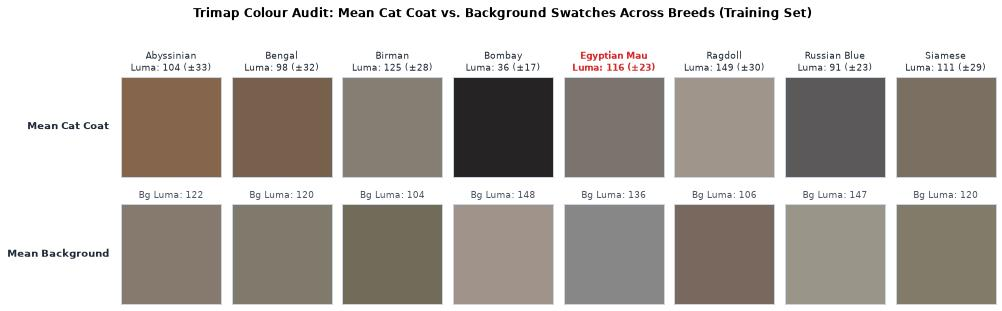

In [59]:
# Compute and visualize mean foreground (cat) and background RGB swatches per breed across training photos.
def mean_colours(name):
    img = np.asarray(inputs.source_photo(name).resize((128, 128)), dtype=np.float32)
    with Image.open(data.trimap_path(name)) as t:
        tri = np.asarray(
            inputs.square(t.convert("L"), Image.Resampling.NEAREST)
            .resize((128, 128), Image.Resampling.NEAREST)
        )
    pet, bg = tri == inputs.TRIMAP_PET, tri == 2
    cat = img[pet].mean(axis=0) if pet.any() else np.full(3, np.nan)
    back = img[bg].mean(axis=0) if bg.any() else np.full(3, np.nan)
    return cat, back


train_df = photos_df[photos_df["role"] == "train"]
colours = {}
for breed in CLASSES:
    cats, backs = zip(*[mean_colours(n) for n in train_df.loc[train_df["breed"] == breed, "image"]])
    colours[breed] = (
        np.nanmean(cats, axis=0),
        np.nanmean(backs, axis=0),
        np.nanstd(cats, axis=0).mean(),
    )

fig, axes = plt.subplots(2, len(CLASSES), figsize=(14, 4.4))

for j, breed in enumerate(CLASSES):
    cat, back, spread = colours[breed]
    is_target = (breed == TARGET)

    # Top row: Mean coat colour swatch
    axes[0, j].imshow(np.clip(np.full((10, 10, 3), cat / 255), 0, 1))
    axes[0, j].set_title(
        f"{breed}\nLuma: {cat.mean():.0f} (±{spread:.0f})",
        fontsize=9,
        fontweight="bold" if is_target else "normal",
        color="tab:red" if is_target else "#1f2937",
        pad=6,
    )

    # Bottom row: Mean background colour swatch
    axes[1, j].imshow(np.clip(np.full((10, 10, 3), back / 255), 0, 1))
    axes[1, j].set_title(
        f"Bg Luma: {back.mean():.0f}",
        fontsize=8.5,
        color="#4b5563",
        pad=6,
    )

# Clean borders around swatches so bright/cream coats (like Siamese) don't blend into the white page
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor("#cbd5e1")
        spine.set_linewidth(1)

# Left-aligned row labels
row_titles = ["Mean Cat Coat", "Mean Background"]
for r, label in enumerate(row_titles):
    axes[r, 0].text(
        -0.12, 0.5, label,
        transform=axes[r, 0].transAxes,
        ha="right", va="center",
        fontsize=9.5,
        fontweight="bold",
        color="#1f2937",
    )

fig.suptitle(
    "Trimap Colour Audit: Mean Cat Coat vs. Background Swatches Across Breeds (Training Set)",
    fontsize=11.5,
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
plt.show()

What the colour audit shows:

* **Egyptian Mau's mean coat (luma 116) sits between its look-alikes:** lighter than Russian Blue (91), and greyer than the warm brown Abyssinian (104) and Bengal (98). On mean colour alone it is closest to Siamese (111) and Birman (125), breeds it looks nothing like, so average colour is a weak breed cue; the spot pattern has to carry the identity.
* **Mau has the smallest colour spread of the patterned breeds (±23)**, because 13 of its 15 training photos are silver. A bronze Mau in validation or test has almost no training counterpart (see 2.5).
* **No strong background shortcut is visible in the means.** All mean backgrounds are neutral grey-brown (luma 104–148). The two darkest-coated breeds, Bombay and Russian Blue, have the lightest backgrounds (148 and 147), which is photographers choosing contrast, not a breed cue the classifier could exploit on its own. Means can't rule out subtler cues (studio backdrops, furniture), which is why the grids in 2.3 and 2.5 are inspected by eye.

### 2.5 The 15 *Egyptian Mau* training photos versus validation and test

These 15 images are **the entire visual universe** available to our data-augmentation pipelines: oversampling repeats them, classical augmentation warps them, and every image-conditioned diffusion mode (img2img, IP-Adapter, inpainting) uses them as its starting point. Below them sit the 20 validation and 30 test *Egyptian Maus* on which the classifier is ultimately judged.

Comparing these sets reveals the core bottleneck of low-shot learning: any visual variation present in validation or test—a different coat hue (silver vs. bronze), an unseen pose, or an outdoor setting—that is missing from these 15 seeds **can only partly be reached by methods anchored to these photos**. Oversampling and augmentation can't create it at all; img2img keeps each photo's layout; IP-Adapter, outpainting and text-to-image are the methods with the freedom to invent poses, framings and scenes beyond the 15 photos.

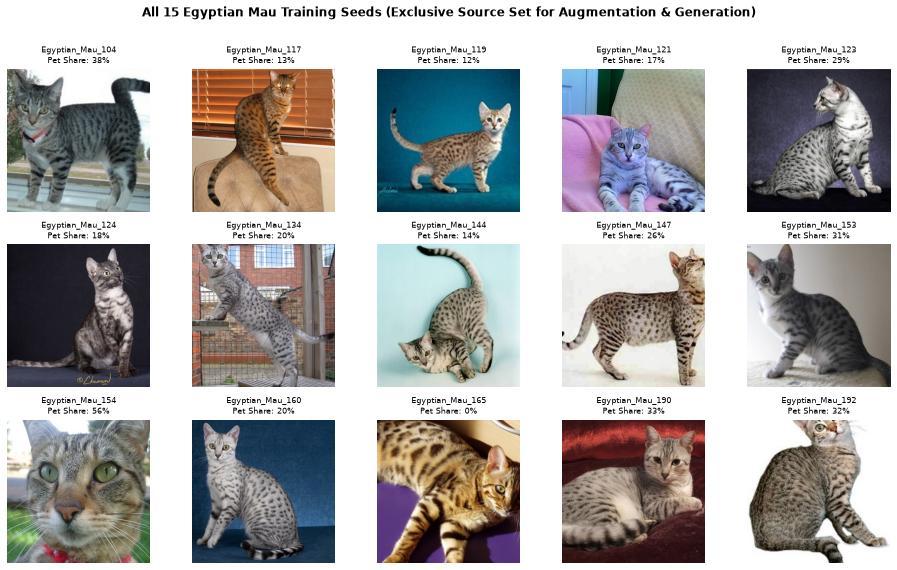

In [60]:
# Display all 15 Egyptian Mau training seed images
mau_train = data.minority_training_photos()
shares = photos_df.set_index("image")["pet_share"]

show_grid(
    mau_train,
    ncols=5,
    titles=[f"{n}\nPet Share: {shares[n]:.0%}" for n in mau_train],
    size=2.6,
    suptitle="All 15 Egyptian Mau Training Seeds (Exclusive Source Set for Augmentation & Generation)",
)

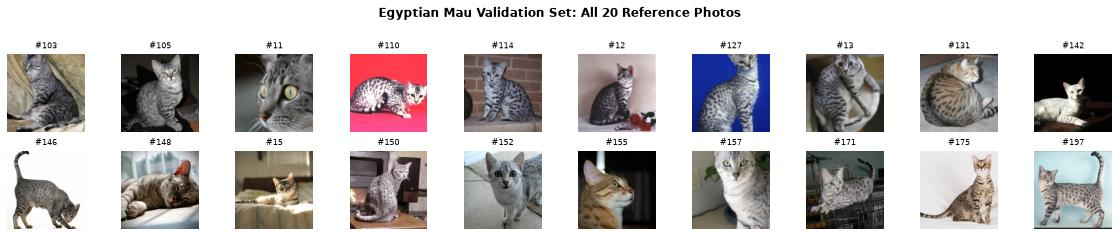

In [61]:
# Display all 20 Egyptian Mau validation photos
mau_val = split.query("breed == @TARGET and role == 'val'")["image"].tolist()

show_grid(
    mau_val,
    ncols=10,
    titles=[n.replace("Egyptian_Mau_", "#") for n in mau_val],
    size=1.6,
    suptitle="Egyptian Mau Validation Set: All 20 Reference Photos",
)

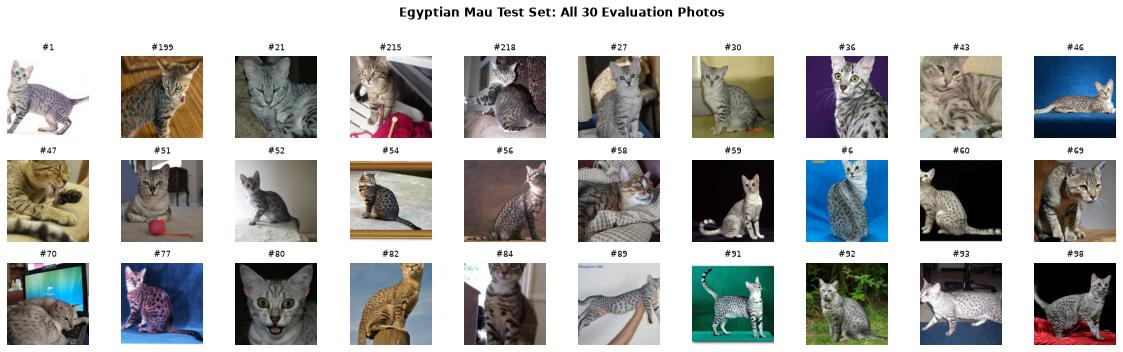

In [62]:
# Display all 30 Egyptian Mau test photos
mau_test = split.query("breed == @TARGET and role == 'test'")["image"].tolist()

show_grid(
    mau_test,
    ncols=10,
    titles=[n.replace("Egyptian_Mau_", "#") for n in mau_test],
    size=1.6,
    suptitle="Egyptian Mau Test Set: All 30 Evaluation Photos",
)

What the three grids show, by eye:

* **Coat colour.** 13 of the 15 training Maus are silver with dark spots; only two are bronze/golden (#117 and #165). Validation and test contain warm-toned Maus too (clearly validation #155 and test #82), so a bronze Mau is rare in training but not in evaluation.
* **Framing and pose.** The training photos are mostly whole cats, standing or sitting, seen from the side; only one is a face close-up (#154) and three are lying down (#121, #165, #190). Validation and test have more close-ups (val #11, #155; test #80, #36), lying or curled cats (val #131, #148, #15; test #47, #58, #43) and cats facing the camera (val #152, #157).
* **Backgrounds.** 7 of the 15 training photos are studio or cut-out shots on a plain backdrop (#119, #123, #124, #144, #147, #160, #192). Validation and test have more cluttered homes (beds, sofas, desks with a computer) and a few outdoor shots (test #92 on grass).
* **Unusual subjects.** Test includes a human arm (#89) and a cat with a ball of yarn (#51); there is no such photo in training.
* **Likely blind spots.** Photos with no close counterpart among the 15: the bronze head portrait (val #155), the small cat far away on a bed (val #15), the sleeping and curled cats (val #148, #131), the extreme face close-up (val #11). Section 2.6 checks whether the frozen backbone also finds these photos hard.

### 2.6 Feature space: how the pretrained backbone sees the breeds

Before a single weight is fine-tuned, our **EfficientNet-B0** backbone—pretrained on ImageNet—already maps images into a 1280-dimensional space sensitive to fur texture, facial geometry, and coat markings. Embedding every training photo with this frozen network shows us the model's "starting map" of the dataset: whether breeds separate cleanly out of the box, and whether *Egyptian Mau* sits next to the exact visual look-alikes we spotted by eye (Bengal, Abyssinian, and Russian Blue).

We inspect this frozen feature space through three complementary lenses:
* **2D PCA Projection:** Maps the global geometry of the training set to reveal cluster spread, overlap, and whether the 15 *Egyptian Mau* seeds occupy a tight corner or scatter across neighbouring breeds.
* **Centroid Cosine Similarity:** Quantifies pairwise proximity between breed averages, giving an exact ranking of *Egyptian Mau's* closest feature-space neighbours.
* **Zero-Training Baselines (Imbalance-Neutral vs. Imbalance-Sensitive):**
    * **Nearest Centroid:** Classifies each validation/test image by its closest breed average—collapsing each class to a single prototype so the **15-vs-70 sample imbalance** has zero effect.
    * **1-Nearest Neighbour (1-NN):** Classifies by the single closest training image—exposing the raw **density disadvantage** of the minority class, where every *Egyptian Mau* query faces 490 majority-class candidates against only 15 true matches.

In [63]:
# Extract L2-normalized 1280-D feature embeddings for all train and validation images using the frozen EfficientNet-B0 backbone.
device = T.pick_device("auto")
backbone = T.build_model("efficientnet_b0")
backbone.classifier = torch.nn.Identity()  # Expose 1280-D feature vector before the 8-class head
backbone = backbone.to(device).eval()

cache = T.photo_cache(("train", "val", "test"))


@torch.no_grad()
def embed(names, batch=64):
    feats = []
    for i in range(0, len(names), batch):
        x = torch.stack([torch.as_tensor(T.EVAL_TRANSFORM(cache[n])) for n in names[i:i + batch]]).to(device)
        f = backbone(x).float().cpu()
        feats.append(torch.nn.functional.normalize(f, dim=1))
    return torch.cat(feats).numpy()


names_train = split.loc[split["role"] == "train", "image"].tolist()
labels_train = split.loc[split["role"] == "train", "breed"].map(CLASSES.index).to_numpy()
names_val = split.loc[split["role"] == "val", "image"].tolist()
labels_val = split.loc[split["role"] == "val", "breed"].map(CLASSES.index).to_numpy()

F_train, F_val = embed(names_train), embed(names_val)

print(
    f"Device: {device} | "
    f"Train Embeddings: {F_train.shape[0]} images x {F_train.shape[1]} dims | "
    f"Val Embeddings: {F_val.shape[0]} images x {F_val.shape[1]} dims"
)

Device: mps | Train Embeddings: 505 images x 1280 dims | Val Embeddings: 160 images x 1280 dims


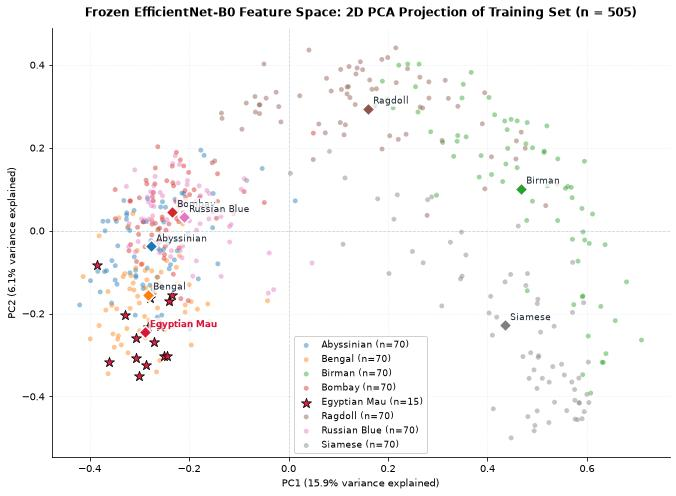

In [64]:
# Project 1280-D frozen EfficientNet-B0 training embeddings onto their top two principal components and plot breed clusters.
centered = F_train - F_train.mean(axis=0)
_, s, vt = np.linalg.svd(centered, full_matrices=False)
proj = centered @ vt[:2].T

# Compute variance explained by PC1 and PC2
var_explained = (s ** 2) / np.sum(s ** 2)

fig, ax = plt.subplots(figsize=(9.5, 7))
palette = plt.get_cmap("tab10")

for k, breed in enumerate(CLASSES):
    m = labels_train == k
    is_target = (breed == TARGET)
    color = "crimson" if is_target else palette(k)

    ax.scatter(
        proj[m, 0],
        proj[m, 1],
        s=110 if is_target else 24,
        alpha=0.95 if is_target else 0.45,
        color=color,
        edgecolors="black" if is_target else "none",
        linewidths=0.8 if is_target else 0,
        label=f"{breed} (n={m.sum()})",
        marker="*" if is_target else "o",
        zorder=5 if is_target else 2,
    )

    # Plot and label each breed's 2D centroid for immediate spatial orientation
    cx, cy = proj[m, 0].mean(), proj[m, 1].mean()
    ax.scatter(
        cx, cy,
        s=80,
        color=color,
        edgecolors="white",
        linewidths=1.5,
        marker="D",
        zorder=6,
    )
    ax.annotate(
        breed,
        (cx, cy),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold" if is_target else "medium",
        color="crimson" if is_target else "#1f2937",
        bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.75),
        zorder=7,
    )

ax.axhline(0, color="#cbd5e1", linestyle="--", linewidth=0.8, zorder=1)
ax.axvline(0, color="#cbd5e1", linestyle="--", linewidth=0.8, zorder=1)
ax.grid(True, linestyle=":", alpha=0.45, color="#cbd5e1")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlabel(f"PC1 ({var_explained[0]:.1%} variance explained)", fontsize=10)
ax.set_ylabel(f"PC2 ({var_explained[1]:.1%} variance explained)", fontsize=10)
ax.set_title(
    "Frozen EfficientNet-B0 Feature Space: 2D PCA Projection of Training Set (n = 505)",
    fontsize=11.5,
    fontweight="bold",
    pad=12,
)
ax.legend(loc="best", frameon=True, facecolor="white", framealpha=0.9, fontsize=8.5)

fig.tight_layout()
plt.show()

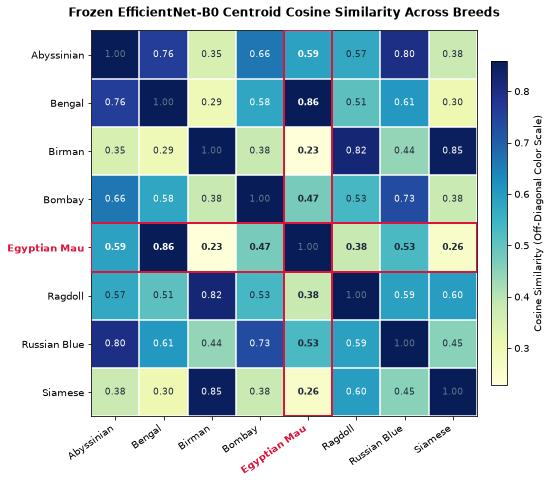

,1st Nearest Neighbour,2nd Nearest Neighbour,3rd Nearest Neighbour
Breed,,,
Abyssinian,Russian Blue (0.798),Bengal (0.761),Bombay (0.662)
Bengal,Egyptian Mau (0.858),Abyssinian (0.761),Russian Blue (0.606)
Birman,Siamese (0.848),Ragdoll (0.821),Russian Blue (0.440)
Bombay,Russian Blue (0.733),Abyssinian (0.662),Bengal (0.577)
Egyptian Mau,Bengal (0.858),Abyssinian (0.586),Russian Blue (0.530)
Ragdoll,Birman (0.821),Siamese (0.595),Russian Blue (0.588)
Russian Blue,Abyssinian (0.798),Bombay (0.733),Bengal (0.606)
Siamese,Birman (0.848),Ragdoll (0.595),Russian Blue (0.452)


In [65]:
# Compute pairwise cosine similarity between L2-normalized breed centroids and display a heatmap plus nearest-neighbour table.
centroids = np.stack([F_train[labels_train == k].mean(axis=0) for k in range(len(CLASSES))])
centroids /= np.linalg.norm(centroids, axis=1, keepdims=True)
sim = centroids @ centroids.T

n_classes = len(CLASSES)
target_idx = CLASSES.index(TARGET)

# Scale colormap to the off-diagonal range so subtle pairwise differences stand out
off_diag = sim[~np.eye(n_classes, dtype=bool)]
vmin, vmax = off_diag.min(), off_diag.max()

fig, ax = plt.subplots(figsize=(8, 6.8))
im = ax.imshow(sim, cmap="YlGnBu", vmin=vmin, vmax=vmax)

# Cell values with adaptive contrast
midpoint = vmin + 0.55 * (vmax - vmin)
for i in range(n_classes):
    for j in range(n_classes):
        is_diag = (i == j)
        val_text = "1.00" if is_diag else f"{sim[i, j]:.2f}"
        ax.text(
            j, i,
            val_text,
            ha="center", va="center",
            fontsize=8.5,
            fontweight="bold" if (i == target_idx or j == target_idx) and not is_diag else "normal",
            color="#64748b" if is_diag else ("white" if sim[i, j] > midpoint else "#1e293b"),
        )

# Subtle white borders between tiles + highlight frame around Egyptian Mau row/column
ax.set_xticks(np.arange(-0.5, n_classes, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_classes, 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=1.5)
ax.tick_params(which="minor", bottom=False, left=False)

rect_row = Rectangle((-0.5, target_idx - 0.5), n_classes, 1, fill=False, edgecolor="crimson", linewidth=2, zorder=4)
rect_col = Rectangle((target_idx - 0.5, -0.5), 1, n_classes, fill=False, edgecolor="crimson", linewidth=2, zorder=4)
ax.add_patch(rect_row)
ax.add_patch(rect_col)

ax.set_xticks(range(n_classes))
ax.set_xticklabels(CLASSES, rotation=35, ha="right", fontsize=9.5)
ax.set_yticks(range(n_classes))
ax.set_yticklabels(CLASSES, fontsize=9.5)

for tick in ax.get_xticklabels():
    if tick.get_text() == TARGET:
        tick.set_color("crimson")
        tick.set_fontweight("bold")
for tick in ax.get_yticklabels():
    if tick.get_text() == TARGET:
        tick.set_color("crimson")
        tick.set_fontweight("bold")

cbar = fig.colorbar(im, ax=ax, shrink=0.82, pad=0.03)
cbar.set_label("Cosine Similarity (Off-Diagonal Color Scale)", fontsize=9.5)

ax.set_title(
    "Frozen EfficientNet-B0 Centroid Cosine Similarity Across Breeds",
    fontsize=11.5,
    fontweight="bold",
    pad=14,
)
fig.tight_layout()
plt.show()

# Publication-ready summary table of the top 3 nearest neighbours per breed
rows = []
for i, breed in enumerate(CLASSES):
    order = [j for j in np.argsort(-sim[i]) if j != i][:3]
    rows.append({
        "Breed": breed,
        "1st Nearest Neighbour": f"{CLASSES[order[0]]} ({sim[i, order[0]]:.3f})",
        "2nd Nearest Neighbour": f"{CLASSES[order[1]]} ({sim[i, order[1]]:.3f})",
        "3rd Nearest Neighbour": f"{CLASSES[order[2]]} ({sim[i, order[2]]:.3f})",
    })

nn_df = pd.DataFrame(rows).set_index("Breed")
display(
    nn_df.style
    .set_caption("Top 3 Nearest Breed Centroids in Frozen EfficientNet-B0 Feature Space (Cosine Similarity)")
    .apply(
        lambda s: ["background-color: #fee2e2; font-weight: bold; color: #991b1b" if s.name == TARGET else "" for _ in s],
        axis=1,
    )
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "11pt"), ("font-weight", "bold"), ("margin-bottom", "8px"), ("text-align", "left")]},
        {"selector": "th", "props": [("text-align", "left"), ("padding", "6px 10px"), ("background-color", "#f8fafc"), ("border-bottom", "1px solid #cbd5e1")]},
        {"selector": "td", "props": [("padding", "6px 10px"), ("border-bottom", "1px solid #e2e8f0")]},
    ])
)

In [66]:
# 3. Training-free classifiers: nearest centroid (prior-free) vs 1-NN (imbalanced)
from synthdata.metrics import summary as metric_summary

nc_val = np.argmax(F_val @ centroids.T, axis=1)
nn_val = labels_train[np.argmax(F_val @ F_train.T, axis=1)]

S = F_train @ F_train.T
np.fill_diagonal(S, -np.inf)
nn_train = labels_train[np.argmax(S, axis=1)]


def confusion_frame(labels, preds):
    m = np.array(metric_summary(labels, preds)["confusion"])
    return pd.DataFrame(m, index=[f"true {c}" for c in CLASSES], columns=CLASSES)


for title, lab, pred in [("nearest centroid on the 160 validation photos (no class prior)", labels_val, nc_val),
                         ("1-NN on the 160 validation photos (neighbours from the imbalanced training set)", labels_val, nn_val),
                         ("1-NN leave-one-out over the 505 training photos", labels_train, nn_train)]:
    s = metric_summary(lab, pred)
    print(f"{title}\n  Mau recall {s['egyptian_mau_recall']:.2f} | macro-F1 {s['macro_f1']:.3f} | accuracy {s['accuracy']:.3f}")
    print("  per-breed recall:", {b: round(v, 2) for b, v in s["recall"].items()})
    print()

confusion_frame(labels_val, nc_val).style.set_caption("Nearest centroid, validation: rows = true breed")

nearest centroid on the 160 validation photos (no class prior)
  Mau recall 0.85 | macro-F1 0.879 | accuracy 0.881
  per-breed recall: {'Abyssinian': 0.95, 'Bengal': 0.65, 'Birman': 0.85, 'Bombay': 1.0, 'Egyptian Mau': 0.85, 'Ragdoll': 0.9, 'Russian Blue': 1.0, 'Siamese': 0.85}

1-NN on the 160 validation photos (neighbours from the imbalanced training set)
  Mau recall 0.75 | macro-F1 0.868 | accuracy 0.869
  per-breed recall: {'Abyssinian': 0.85, 'Bengal': 0.7, 'Birman': 0.9, 'Bombay': 1.0, 'Egyptian Mau': 0.75, 'Ragdoll': 0.85, 'Russian Blue': 0.9, 'Siamese': 1.0}

1-NN leave-one-out over the 505 training photos
  Mau recall 0.80 | macro-F1 0.845 | accuracy 0.865
  per-breed recall: {'Abyssinian': 0.81, 'Bengal': 0.79, 'Birman': 0.89, 'Bombay': 0.97, 'Egyptian Mau': 0.8, 'Ragdoll': 0.86, 'Russian Blue': 0.96, 'Siamese': 0.8}



,Abyssinian,Bengal,Birman,Bombay,Egyptian Mau,Ragdoll,Russian Blue,Siamese
true Abyssinian,19,0,0,0,0,0,1,0
true Bengal,3,13,0,1,3,0,0,0
true Birman,0,0,17,0,0,2,0,1
true Bombay,0,0,0,20,0,0,0,0
true Egyptian Mau,1,2,0,0,17,0,0,0
true Ragdoll,0,0,2,0,0,18,0,0
true Russian Blue,0,0,0,0,0,0,20,0
true Siamese,0,0,3,0,0,0,0,17


In [67]:
# Display the styled 1-Nearest Neighbour validation confusion matrix, highlighting the Egyptian Mau target row.
cm_val = confusion_frame(labels_val, nn_val)

display(
    cm_val.style
    .set_caption("1-Nearest Neighbour (1-NN) Validation Confusion Matrix — Rows = True Breed, Columns = Predicted Breed")
    .background_gradient(cmap="Blues", axis=None, low=0.05, high=0.85)
    .format("{:.0f}")
    .apply_index(
        lambda idx: [
            "background-color: #fee2e2; color: #991b1b; font-weight: bold" if v == TARGET else ""
            for v in idx
        ],
        axis=0,
    )
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "11pt"), ("font-weight", "bold"), ("margin-bottom", "8px"), ("text-align", "left")]},
        {"selector": "th.row_heading", "props": [("text-align", "left"), ("padding", "6px 10px"), ("background-color", "#f8fafc"), ("border-bottom", "1px solid #cbd5e1")]},
        {"selector": "th.col_heading", "props": [("text-align", "center"), ("padding", "6px 8px"), ("background-color", "#f8fafc"), ("border-bottom", "1px solid #cbd5e1"), ("font-size", "8.5pt")]},
        {"selector": "td", "props": [("text-align", "center"), ("padding", "6px 8px"), ("border-bottom", "1px solid #e2e8f0")]},
    ])
)

,Abyssinian,Bengal,Birman,Bombay,Egyptian Mau,Ragdoll,Russian Blue,Siamese
true Abyssinian,17,1,0,0,0,2,0,0
true Bengal,3,14,0,1,2,0,0,0
true Birman,0,0,18,0,0,2,0,0
true Bombay,0,0,0,20,0,0,0,0
true Egyptian Mau,2,2,0,0,15,0,1,0
true Ragdoll,0,0,3,0,0,17,0,0
true Russian Blue,1,0,0,1,0,0,18,0
true Siamese,0,0,0,0,0,0,0,20


In [68]:
# Rank all 20 validation Egyptian Maus by cosine similarity margin between the Mau centroid and the closest competing breed.
mau_val_idx = np.where(labels_val == CLASSES.index(TARGET))[0]
sims = F_val[mau_val_idx] @ centroids.T

closest = pd.DataFrame(
    sims,
    index=[names_val[i].replace("Egyptian_Mau_", "#") for i in mau_val_idx],
    columns=CLASSES,
)
MARGIN = "Margin (Mau − Best Other)"
closest["Nearest Centroid"] = closest.idxmax(axis=1)
closest[MARGIN] = (
    closest[TARGET] - closest.drop(columns=[TARGET, "Nearest Centroid"]).max(axis=1)
)
closest = closest.sort_values(MARGIN)

display(
    closest.style
    .set_caption("Validation Egyptian Mau Proximity to Breed Centroids (Sorted Worst-to-Best Margin)")
    .format("{:.3f}", subset=[*CLASSES, MARGIN])
    .background_gradient(
        cmap="RdYlGn",
        subset=[MARGIN],
        vmin=-0.08,
        vmax=0.08,
    )
    .apply(
        lambda col: [
            "background-color: #fee2e2; color: #991b1b; font-weight: bold" if val != TARGET else "font-weight: bold; color: #166534"
            for val in col
        ],
        subset=["Nearest Centroid"],
    )
    .apply_index(
        lambda cols: [
            "background-color: #fef2f2; color: #991b1b; font-weight: bold" if c == TARGET else ""
            for c in cols
        ],
        axis=1,
    )
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "11pt"), ("font-weight", "bold"), ("margin-bottom", "8px"), ("text-align", "left")]},
        {"selector": "th.row_heading", "props": [("text-align", "left"), ("padding", "5px 10px"), ("background-color", "#f8fafc"), ("border-bottom", "1px solid #cbd5e1"), ("font-weight", "bold")]},
        {"selector": "th.col_heading", "props": [("text-align", "center"), ("padding", "5px 8px"), ("background-color", "#f8fafc"), ("border-bottom", "1px solid #cbd5e1"), ("font-size", "8.5pt")]},
        {"selector": "td", "props": [("text-align", "center"), ("padding", "5px 8px"), ("border-bottom", "1px solid #e2e8f0")]},
    ])
)

,Abyssinian,Bengal,Birman,Bombay,Egyptian Mau,Ragdoll,Russian Blue,Siamese,Nearest Centroid,Margin (Mau − Best Other)
#155,0.646,0.641,0.197,0.349,0.512,0.388,0.501,0.187,Abyssinian,-0.134
#15,0.538,0.622,0.269,0.414,0.541,0.459,0.501,0.235,Bengal,-0.081
#148,0.476,0.569,0.244,0.316,0.555,0.404,0.495,0.223,Bengal,-0.014
#11,0.519,0.620,0.190,0.416,0.630,0.329,0.547,0.200,Egyptian Mau,0.010
#171,0.433,0.606,0.162,0.412,0.633,0.329,0.389,0.161,Egyptian Mau,0.027
#131,0.328,0.693,0.091,0.276,0.739,0.215,0.251,0.110,Egyptian Mau,0.046
#152,0.506,0.624,0.185,0.346,0.674,0.349,0.471,0.196,Egyptian Mau,0.050
#103,0.471,0.665,0.161,0.354,0.717,0.303,0.433,0.198,Egyptian Mau,0.052
#157,0.441,0.630,0.147,0.310,0.681,0.307,0.458,0.152,Egyptian Mau,0.052
#110,0.360,0.635,0.133,0.325,0.687,0.257,0.289,0.140,Egyptian Mau,0.052


What the three diagnostics show, before a single gradient step:

1. **The look-alike is Bengal, not the whole neighbourhood.** In the frozen feature space Egyptian Mau's centroid is very close to Bengal (cosine 0.858, the closest pair of any two breeds; next is Birman–Siamese at 0.848) and much further from Abyssinian (0.586) and Russian Blue (0.530). In the PCA plot the 15 Mau stars sit at the bottom edge of the Bengal cloud. So of the three look-alikes found by eye in 2.3, the pretrained network agrees strongly only with Bengal: it reacts to the *spotted pattern* more than to the silver colour or the slim build.
2. **Without the imbalance, the breed is recognisable.** The nearest-centroid classifier, which gives every breed one prototype and so ignores the 15-vs-70 imbalance, finds **0.85** of the validation Maus (17 of 20) at 0.879 macro-F1. Its 3 misses go to Bengal (2) and Abyssinian (1). Bengal itself is the weakest breed here (0.65 recall), because 3 Bengals are called Mau and 3 Abyssinian.
3. **The imbalance costs about two photos, even without training.** 1-NN on the same features, where every validation Mau competes with 490 majority photos against 15 Maus, finds 0.75 (15 of 20): a drop of 0.10, i.e. 2 photos. This is the density penalty of the imbalance before any fine-tuning.
4. **The hard photos are already visible.** Sorted by margin, three validation Maus are closer to another breed's centroid than to the Mau one: **#155** (Abyssinian, −0.134), **#15** (Bengal, −0.081) and **#148** (Bengal, −0.014); #11, #171 and #131 follow with margins under +0.05. These are the bronze head portrait, the small cat on a bed, the sleeping cat, the face close-up, the cat on a cage and the curled-up cat: the same blind spots found by eye in 2.5.

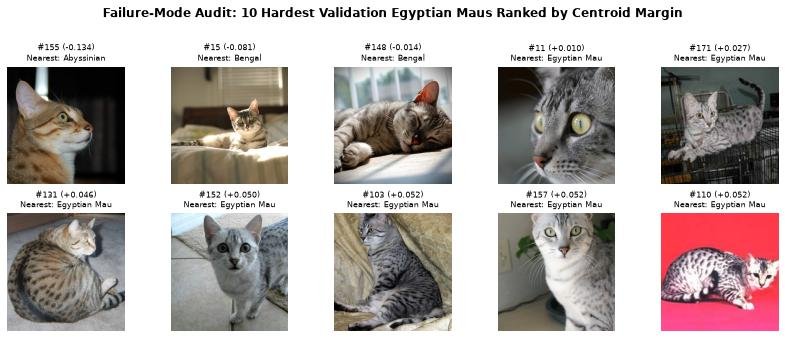

In [69]:
# Display the 10 validation Egyptian Maus with the lowest (or most negative) centroid margin alongside their predicted look-alike breed.
margin_col = "Margin (Mau − Best Other)" if "Margin (Mau − Best Other)" in closest.columns else "margin Mau − best other"
nearest_col = "Nearest Centroid" if "Nearest Centroid" in closest.columns else "nearest"

hard = closest.sort_values(margin_col).index[:10]
hard_names = ["Egyptian_Mau_" + h.lstrip("#") for h in hard]

titles = [
    f"{h} ({closest.loc[h, margin_col]:+.3f})\nNearest: {closest.loc[h, nearest_col]}"
    for h in hard
]

show_grid(
    hard_names,
    ncols=5,
    titles=titles,
    size=2.3,
    suptitle="Failure-Mode Audit: 10 Hardest Validation Egyptian Maus Ranked by Centroid Margin",
)

### 2.7 Trimap annotations: foreground masks and generation risks

Every image in the dataset is paired with a pixel-level **trimap** partitioning the frame into three semantic regions:

* **1 — Pet (Foreground):** Pixels belonging strictly to the cat.
* **2 — Background:** Surrounding environment pixels.
* **3 — Border:** The uncertain transition halo along fur edges and whiskers.

**Why trimap quality matters downstream:** Our synthetic data pipelines rely directly on these masks to preserve subject identity while varying context:
* **`inpaint`:** Masks out both **background (`2`) and border (`3`)** pixels, regenerates the surrounding scene, and composites the untouched **pet (`1`)** foreground back in.
* **`outpaint`:** Scales down the original frame and uses generative fill to extend the outer canvas.

**Quality gate (`MIN_PET_SHARE = 2%`):** Any trimap assigning less than **2%** of total image pixels to the pet mask (`1`) is flagged as corrupted and excluded from foreground-preserving generation. Under this threshold, **`Egyptian_Mau_165`** is automatically skipped by the `inpaint` pipeline—reducing our effective *Egyptian Mau* seed pool for background replacement from **15 down to 14**.

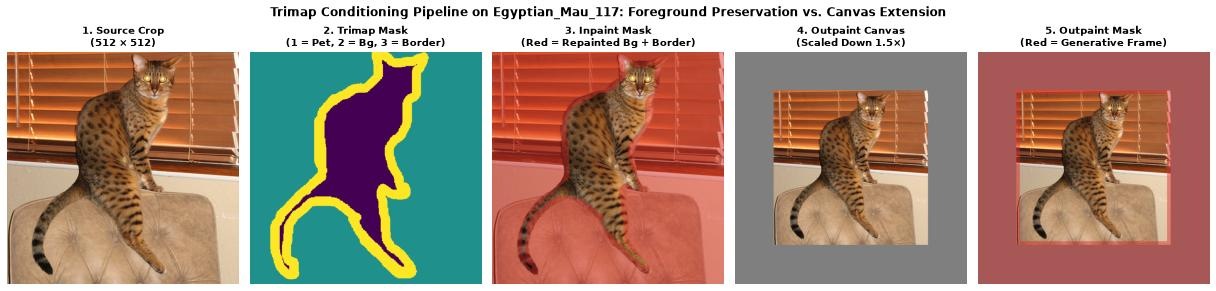

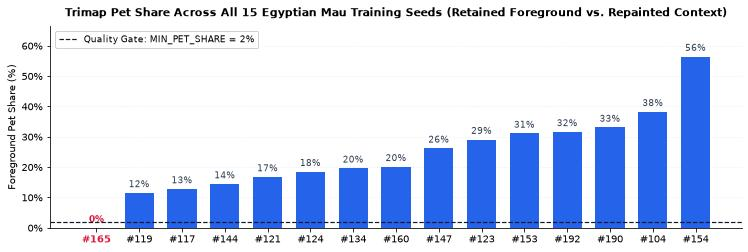

In [70]:
# Inspect trimap masking mechanics (inpaint vs. outpaint) on Egyptian_Mau_117 and audit pet share across all 15 Mau seeds.
example = "Egyptian_Mau_117"
photo = inputs.source_photo(example)
with Image.open(data.trimap_path(example)) as t:
    trimap = inputs.square(t.convert("L"), Image.Resampling.NEAREST)
mask = inputs.background_mask(example)
canvas, out_mask, _, _ = inputs.outpaint_inputs(photo, 1.5)

# 1. Five-panel visual walkthrough of trimap masking for inpainting vs. outpainting
fig, axes = plt.subplots(1, 5, figsize=(17, 4.0))
panels = [
    (photo, "1. Source Crop\n(512 × 512)", None),
    (np.asarray(trimap), "2. Trimap Mask\n(1 = Pet, 2 = Bg, 3 = Border)", "viridis"),
    (inputs.overlay(photo, mask), "3. Inpaint Mask\n(Red = Repainted Bg + Border)", None),
    (canvas, "4. Outpaint Canvas\n(Scaled Down 1.5×)", None),
    (inputs.overlay(canvas, out_mask), "5. Outpaint Mask\n(Red = Generative Frame)", None),
]

for ax, (img, title, cmap) in zip(axes, panels):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title, fontsize=9.5, fontweight="bold", pad=6)
    ax.axis("off")

fig.suptitle(
    f"Trimap Conditioning Pipeline on {example}: Foreground Preservation vs. Canvas Extension",
    fontsize=11.5,
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
plt.show()

# 2. Bar chart of foreground pet share across all 15 Egyptian Mau training seeds
s = shares[mau_train].sort_values()
labels = s.index.str.replace("Egyptian_Mau_", "#")
colors = ["crimson" if v < inputs.MIN_PET_SHARE else "#2563eb" for v in s]

fig, ax = plt.subplots(figsize=(10.5, 3.6))
bars = ax.bar(labels, s * 100, color=colors, width=0.68, edgecolor="none", zorder=3)

ax.axhline(
    inputs.MIN_PET_SHARE * 100,
    color="#111827",
    linestyle="--",
    linewidth=1.2,
    zorder=4,
    label=f"Quality Gate: MIN_PET_SHARE = {inputs.MIN_PET_SHARE:.0%}",
)

# Direct percentage labels above each bar
for bar, val in zip(bars, s):
    is_broken = val < inputs.MIN_PET_SHARE
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.2,
        f"{val:.0%}",
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold" if is_broken else "normal",
        color="crimson" if is_broken else "#334155",
    )

# Highlight broken seed tick label in bold crimson
for tick, val in zip(ax.get_xticklabels(), s):
    if val < inputs.MIN_PET_SHARE:
        tick.set_color("crimson")
        tick.set_fontweight("bold")

ax.set_ylim(0, max(s * 100) + 10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.0f}%"))
ax.grid(axis="y", linestyle=":", alpha=0.5, color="#cbd5e1", zorder=1)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_ylabel("Foreground Pet Share (%)", fontsize=9.5)
ax.set_title(
    "Trimap Pet Share Across All 15 Egyptian Mau Training Seeds (Retained Foreground vs. Repainted Context)",
    fontsize=11,
    fontweight="bold",
    pad=10,
)
ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9, fontsize=9)

fig.tight_layout()
plt.show()

## 3. The split: class imbalance, prior bias and evaluation discipline

| Split Partition | Train | Validation | Test | Total |
| :--- | ---: | ---: | ---: | ---: |
| **Per majority breed** (× 7 breeds) | 70 | 20 | 30 | 120 |
| **Egyptian Mau** (target minority) | **15** | 20 | 30 | 65 |
| **Total images** | **505** | **160** | **240** | **905** |
| **Share of dataset** | 55.8% | 17.7% | 26.5% | 100.0% |

### 3.1 Structural asymmetry and measurement grain

* **Balanced evaluation vs. skewed training:** Validation and test sets are strictly uniform (**12.5%** per breed), whereas *Egyptian Mau* makes up just **3.0%** of the training set (`15 / 505`). Any model that internalizes training frequencies as its class prior is systematically penalized at evaluation time.
* **What synthetic balancing restores:** Adding **55** synthetic or augmented *Egyptian Mau* images (`15 + 55 = 70`) brings the training set to **560** images and restores a uniform **12.5%** class share matching validation and test.
* **Metric granularity:** Because the evaluation sets are compact, individual photos carry noticeable weight:
  * **1 validation *Egyptian Mau*** = **5.0%** (`0.050`) recall.
  * **1 test *Egyptian Mau*** = **3.3%** (`0.033`) recall.
  * Differences of one or two images fall inside single-sample discretization noise and should not be over-interpreted.

### 3.2 How the 70 : 15 imbalance tilts the decision boundary

> **The Base-Rate Trap:** Imagine a classifier that is completely undecided between *Egyptian Mau* and *Bengal* and falls back on training frequency alone. With a **70 : 15** training ratio, it predicts *Bengal* **82.4%** of the time (`70 / 85`) and *Egyptian Mau* only **17.6%** (`15 / 85`).

While gradient descent with cross-entropy does not reduce to a literal lookup table, standard unweighted loss is summed over **490 majority-class examples** against just **15 minority examples**. The resulting gradients push the decision boundary away from the majority clusters and into *Egyptian Mau*'s region—suppressing minority recall even when visual features are clear.

### 3.3 Role of each partition in the experimental protocol

* **`train` (Model construction):** The *only* partition modified across experiments (via resampling, classical augmentation, or synthetic image generation).
* **`val` (Model selection & tuning):** Used repeatedly to compare hyperparameters and augmentation recipes; because selection decisions accumulate over time, validation metrics gradually absorb mild selection optimism.
* **`test` (Final unbiased benchmark):** Held strictly sealed and queried **once per milestone** on the chosen configuration to report an uncontaminated generalization score.

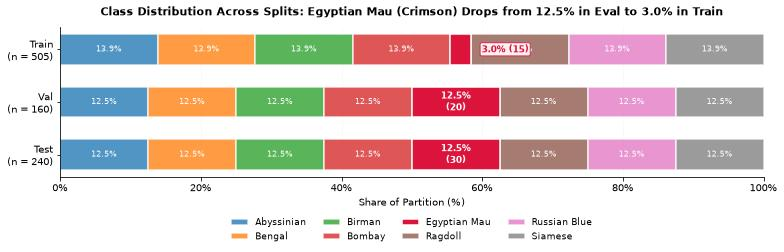

In [71]:
# Plot horizontal stacked bars of breed share across train, validation, and test splits, highlighting the Egyptian Mau prior shift.
roles = pd.crosstab(split["role"], split["breed"]).reindex(["train", "val", "test"])[CLASSES]
shares_by_role = roles.div(roles.sum(axis=1), axis=0)

# Order rows top-to-bottom: train -> val -> test
plot_roles = ["test", "val", "train"]
shares_plot = shares_by_role.loc[plot_roles]
counts_plot = roles.loc[plot_roles]
y_labels = [f"{r.capitalize()}\n(n = {counts_plot.loc[r].sum()})" for r in plot_roles]

fig, ax = plt.subplots(figsize=(11, 3.8))
palette = plt.get_cmap("tab10")
left = np.zeros(len(plot_roles))

for k, breed in enumerate(CLASSES):
    is_target = (breed == TARGET)
    vals = shares_plot[breed].to_numpy()
    cnts = counts_plot[breed].to_numpy()
    color = "crimson" if is_target else palette(k)

    bars = ax.barh(
        y_labels,
        vals,
        left=left,
        height=0.58,
        color=color,
        alpha=1.0 if is_target else 0.78,
        edgecolor="white",
        linewidth=1.5,
        label=breed,
        zorder=3 if is_target else 2,
    )

    # Annotate segment percentages directly inside the bars
    for i, (w, c) in enumerate(zip(vals, cnts)):
        x_center = left[i] + w / 2
        if is_target:
            # Always label Egyptian Mau; place callout just right of the 3% train slice if narrow
            if w < 0.06:
                ax.annotate(
                    f"{w:.1%} ({c})",
                    xy=(left[i] + w, i),
                    xytext=(left[i] + w + 0.015, i),
                    va="center",
                    ha="left",
                    fontsize=8.5,
                    fontweight="bold",
                    color="crimson",
                    bbox=dict(boxstyle="round,pad=0.18", facecolor="#fef2f2", edgecolor="crimson", linewidth=0.8),
                    zorder=5,
                )
            else:
                ax.text(
                    x_center, i,
                    f"{w:.1%}\n({c})",
                    ha="center", va="center",
                    fontsize=8.5,
                    fontweight="bold",
                    color="white",
                    zorder=5,
                )
        elif w >= 0.08:
            ax.text(
                x_center, i,
                f"{w:.1%}",
                ha="center", va="center",
                fontsize=8,
                color="white",
                alpha=0.95,
                zorder=4,
            )

    left += vals

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle=":", alpha=0.45, color="#cbd5e1", zorder=1)

ax.set_xlabel("Share of Partition (%)", fontsize=9.5)
ax.set_title(
    "Class Distribution Across Splits: Egyptian Mau (Crimson) Drops from 12.5% in Eval to 3.0% in Train",
    fontsize=11,
    fontweight="bold",
    pad=12,
)
ax.legend(
    ncol=4,
    fontsize=8.5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    frameon=False,
)

fig.tight_layout()
plt.show()

## 4. The classifier and training protocol

All model construction and training logic lives in `src/synthdata/train.py` and remains **strictly identical across every balancing method**—isolating the effect of the training data itself.

### 4.1 Architecture: EfficientNet-B0 (full fine-tuning)

* **Backbone:** **EfficientNet-B0** (~5.3M parameters), pretrained on ImageNet-1k (1.28M images across 1,000 classes). Five of those classes are domestic cats: tabby, tiger cat, Persian, Siamese and **Egyptian cat**; the last is a loose label for spotted/tabby cats, not a curated breed class, but it means the backbone has seen cats like these before.
* **Classification Head:** The original `1280 → 1000` linear layer is replaced with a randomly initialized `1280 → 8` head.
* **Why transfer learning works here:** As shown in Section 2.6, the frozen ImageNet representation already separates most breeds out of the box, giving fine-tuning a strong geometric head start.

### 4.2 Optimization and training recipe

Every layer in the network is unfrozen and updated end-to-end under a deliberately compact schedule:

| Hyperparameter | Configuration | Methodological Role |
| :--- | :--- | :--- |
| **Loss Function** | Cross-entropy | Multi-class log-loss; each sample pushes up its own class logit relative to the 7 competitors |
| **Optimizer** | AdamW ($\text{lr} = 3 \times 10^{-4}$, weight decay $= 10^{-2}$) | Adaptive per-parameter step sizes paired with decoupled $L_2$ weight regularisation |
| **LR Schedule** | Cosine annealing (8 epochs) | Smoothly decays learning rate from $3 \times 10^{-4}$ down to $0$ |
| **Duration & Batch** | 8 epochs / batch size 64 | $560\text{ images} \rightarrow 9\text{ batches/epoch} \rightarrow \mathbf{72\text{ gradient updates}}$ per balanced run (the imbalanced baseline has 505 images: 8 batches, 64 updates) |
| **Precision** | Mixed precision (`fp16`) on GPU | Accelerates forward/backward passes with negligible numerical drift |
| **Random Seeds** | `0, 1, 2, 3, 4` (5 runs per method) | Controls head initialization, batch shuffle order, and stochastic input transforms |

> **Why only 72 gradient updates?** With just ~500–560 training images and a high-capacity ImageNet backbone, prolonged training risks overfitting to background shortcuts. Keeping optimization short anchors the model close to its pretrained representations—meaning **the visual diversity and fidelity of the training data matter far more than extended optimization could ever compensate for**.

### 4.3 Input preprocessing

All photos are decoded once and cached with their short side resized to **256 px**:

* **Evaluation (`EVAL_TRANSFORM`):** Deterministic `Resize(256)` $\rightarrow$ `CenterCrop(224)` $\rightarrow$ ImageNet channel normalization (`mean`, `std`).
* **Training (`TRAIN_TRANSFORM`):** Applied uniformly to **every** training image (both real and synthetic), regardless of balancing method:

In [72]:
T.TRAIN_TRANSFORM

Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.75, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=(0.85, 1.15), hue=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)

### 4.4 What `TRAIN_TRANSFORM` covers, and where it stops

Every training image passes through a deliberately conservative spatial and photometric pipeline before hitting the network:

| Transform | Configuration | Effect & Analytical Implication |
| :--- | :--- | :--- |
| **`RandomResizedCrop`** | `size=(224, 224)`, `scale=(0.75, 1.0)`, `ratio=(0.75, 1.33)` | Mild random framing (±25% area zoom, slight aspect jitter). Preserves the cat in frame without cropping out small subjects, though background cues remain largely intact. |
| **`RandomHorizontalFlip`** | `p=0.5` | Doubles effective pose symmetry at zero semantic cost. |
| **`ColorJitter`** | `brightness=±15%`, `contrast=±15%`, `saturation=±15%`, `hue=None` | Simulates modest lighting and exposure shifts while **explicitly locking `hue=None`** so tabby/silver coat tints are never artificially shifted toward warmer *Abyssinian* or *Bengal* tones. |
| **`ToTensor` + `Normalize`** | ImageNet `mean` / `std` | Aligns channel statistics with the pretrained EfficientNet-B0 backbone. |

> **Why standard augmentation alone is not enough:** Because every method shares this identical baseline pipeline, `TRAIN_TRANSFORM` acts as a constant control. However, mild crops, flips, and ±15% lighting jitter only perturb pixel framing—they **never introduce new poses, coat patterns, or background environments** beyond the original 15 *Egyptian Mau* seeds. Bridging that diversity gap is the exact role of the balancing and synthetic generation methods tested next.

So a random crop of 75–100% of the area, a random flip and mild colour jitter are *always* applied, including to oversampled copies and to synthetic images. The `augment` method adds `balance.augment()` *before* this: extra random transforms of the added Mau copies, written in the first exercise. Below, what the network actually receives for one Mau photo from `TRAIN_TRANSFORM` alone: six random draws.

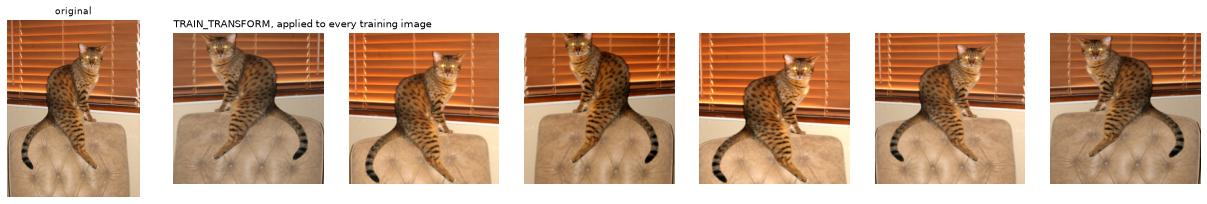

In [73]:
torch.manual_seed(0)
small = T.load_small(data.image_path(example))
mean, std = torch.tensor(T.MEAN)[:, None, None], torch.tensor(T.STD)[:, None, None]


def to_img(t):
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


fig, axes = plt.subplots(1, 7, figsize=(17, 2.9))
axes[0].imshow(small)
axes[0].set_title("original", fontsize=9)
for k in range(1, 7):
    axes[k].imshow(to_img(T.TRAIN_TRANSFORM(small)))
for ax in axes:
    ax.axis("off")
axes[1].set_title("TRAIN_TRANSFORM, applied to every training image", loc="left", fontsize=10)
fig.tight_layout()
plt.show()

### 4.5 Evaluation

 `metrics.summary()` computes, from the confusion matrix: Egyptian Mau recall (the main metric), macro-F1 (the guard), accuracy, per-breed recall. Why two metrics: recall only counts the Maus found; macro-F1 also counts the Bengals and Russian Blues wrongly called Mau. A quick illustration with the course's own code:

In [74]:
MAU, BENGAL = CLASSES.index(TARGET), CLASSES.index("Bengal")
labels = np.repeat(np.arange(8), 20)
cautious = labels.copy(); cautious[np.where(labels == MAU)[0][:10]] = BENGAL   # misses half the Maus
eager = labels.copy();    eager[np.where(labels == BENGAL)[0][:10]] = MAU      # finds all Maus, calls half the Bengals Mau
pd.DataFrame({name: {k: round(v, 3) for k, v in metric_summary(labels, p).items() if k in ("egyptian_mau_recall", "macro_f1", "accuracy")}
              for name, p in [("perfect", labels), ("cautious", cautious), ("eager", eager)]}).T

,egyptian_mau_recall,macro_f1,accuracy
perfect,1.0,1.000,1.000
cautious,0.5,0.933,0.938
eager,1.0,0.933,0.938


Same number of errors, same macro-F1, opposite Mau recall. A gain in Mau recall that comes with a loss in Bengal recall is a shifted decision boundary, not a better model, and the confusion matrix is where that shows.

## 5. The methods, exercise by exercise

### 5.1 Meeting 1: oversampling and augmentation

Two classical answers to class imbalance, used to measure what *no new information* achieves:

- **Oversampling** repeats the 15 photos to reach 70 (55 = 3·15 + 10, the 10 that get a 4th copy chosen by the seeded `rng`). It changes only how often the model sees a Mau, i.e. the class prior in the loss.
- **Augmentation** repeats them too, but each added copy is re-transformed every time it is loaded. The model sees the same cat flipped, tilted, shifted and re-lit. Hue should stay untouched, because coat colour is a breed cue (2.4).

**What I expect, based on this exploration:**

1. **The imbalanced baseline will be clearly worse than the training-free classifiers of 2.6.** Nearest centroid finds 0.85 of the validation Maus and 1-NN 0.75; with the loss summed over 490 majority photos against 15 Maus (3.2), fine-tuning should push the boundary further into the Mau region. I expect Mau recall around or below 0.6, with the missed Maus going mostly to Bengal, the closest centroid.
2. **Oversampling will recover most of that gap.** If the problem is the prior, balancing the class frequency fixes it without any new information. Mau recall should move towards the nearest-centroid level.
3. **Augmentation will add little on top of oversampling.** `TRAIN_TRANSFORM` (4.4) already crops, flips and re-lights every image, so oversampled copies are never identical at the network's input; extra mild transforms add more of the same.
4. **The hard photos will stay hard.** #155, #15 and #148 sit closer to another breed than to Egyptian Mau before training (2.6), and they show views the 15 training photos don't contain (2.5). Neither repeating nor re-lighting those 15 photos can create a bronze head portrait or a distant cat on a bed, so I expect a ceiling below 1.0 that only new images could lift.
5. **Gains in Mau recall will cost some Bengal recall.** Mau and Bengal are the closest pair in feature space, so a model that says "Mau" more often will also say it for some Bengals. Macro-F1 should still rise, because the baseline loses many more Maus than balancing will cost Bengals.

### 5.2 Diffusion models in one page

A diffusion model learns to **reverse a gradual noising process**.

**Forward process (fixed).** Take a clean image $x_0$ and mix in Gaussian noise over $T = 1000$ steps. In closed form, for any step $t$:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\qquad \varepsilon\sim\mathcal N(0, I)$$

where $\bar\alpha_t$ falls from ≈1 (clean) to ≈0 (pure noise) along a fixed noise schedule.

**Reverse process (learned).** A network $\varepsilon_\theta(x_t, t, c)$ is trained to predict the noise $\varepsilon$ that was added, given the noisy image, the step, and a condition $c$ (the text). Loss: $\lVert \varepsilon - \varepsilon_\theta(x_t, t, c) \rVert^2$. To generate: start from pure noise $x_T$, predict the noise, remove a bit of it, repeat. The **sampler/scheduler** (DDIM, Euler, DPM-Solver++) is the numerical rule for how much to remove per step, which is why 30 steps suffice instead of 1000.

**Latent diffusion (Stable Diffusion).** Doing this on 512×512×3 pixels is slow, so SD works in the latent space of a **VAE**: the image is encoded to a 64×64×4 latent, diffusion runs there, and the decoder turns the final latent back into pixels.

| Part | Role |
| --- | --- |
| **Text encoder** (CLIP ViT-L/14 in SD 1.5; two CLIP encoders in SDXL) | turns the prompt into token embeddings $c$ |
| **U-Net** | the noise predictor $\varepsilon_\theta$; attends to $c$ through **cross-attention** layers |
| **VAE** | encodes photos to latents (img2img, inpainting start here) and decodes latents to images |

**Classifier-free guidance (CFG).** The U-Net is run twice per step, with the prompt and with an empty (or negative) prompt, and the difference is amplified:

$$\hat\varepsilon = \varepsilon_\theta(x_t, \varnothing) + w\,[\varepsilon_\theta(x_t, c) - \varepsilon_\theta(x_t, \varnothing)]$$

$w$ is `--guidance`. The `--negative-prompt` replaces $\varnothing$, so the image is pushed *away* from "illustration, cartoon, text, extra limbs".

Below, the forward process applied to a real Mau photo with SD's own schedule (`scaled_linear`, β from 0.00085 to 0.012), in pixel space for visibility.

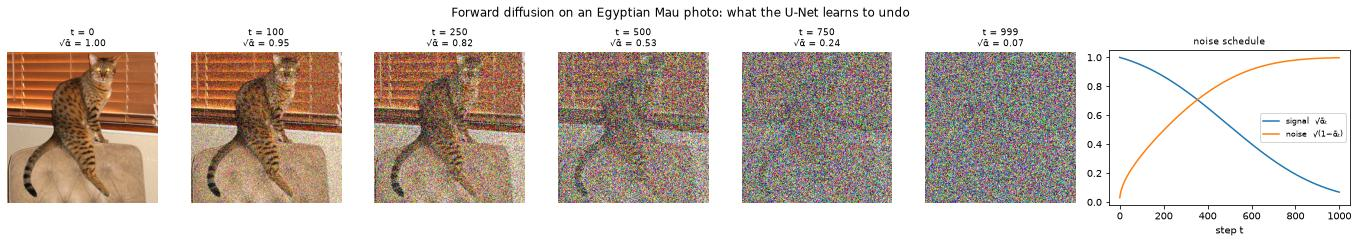

In [75]:
T_STEPS = 1000
betas = np.linspace(0.00085 ** 0.5, 0.012 ** 0.5, T_STEPS) ** 2
alpha_bar = np.cumprod(1 - betas)

x0 = np.asarray(photo.resize((256, 256)), dtype=np.float32) / 127.5 - 1
noise = np.random.default_rng(0).standard_normal(x0.shape).astype(np.float32)
steps = [0, 100, 250, 500, 750, 999]

fig, axes = plt.subplots(1, len(steps) + 1, figsize=(19, 3.4), gridspec_kw={"width_ratios": [1] * len(steps) + [1.6]})
for ax, t in zip(axes, steps):
    xt = np.sqrt(alpha_bar[t]) * x0 + np.sqrt(1 - alpha_bar[t]) * noise
    ax.imshow(((xt + 1) / 2).clip(0, 1))
    ax.set_title(f"t = {t}\n√ᾱ = {np.sqrt(alpha_bar[t]):.2f}", fontsize=9)
    ax.axis("off")
axes[-1].plot(np.sqrt(alpha_bar), label="signal  √ᾱₜ")
axes[-1].plot(np.sqrt(1 - alpha_bar), label="noise  √(1−ᾱₜ)")
axes[-1].set_xlabel("step t")
axes[-1].legend(fontsize=8)
axes[-1].set_title("noise schedule", fontsize=9)
fig.suptitle("Forward diffusion on an Egyptian Mau photo: what the U-Net learns to undo")
fig.tight_layout()
plt.show()

Fine detail (spots, fur) fades by t ≈ 250 and is gone by t ≈ 500; the coarse layout (where the cat is, its colours) is still visible at t ≈ 500 and gone by t ≈ 750. (This is in pixel space; Stable Diffusion noises a 64×64 latent, so the exact steps differ, but the order is the same.) This ordering, coarse structure last to go and first to come back, is what the img2img `strength` knob in 5.4 exploits.

### 5.3 Meeting 2: text-to-image (`--mode t2i`)

**What it is meant to test:** whether images with *no* connection to the 15 photos, only to the words "Egyptian Mau" as the model learned them from captioned web images, can teach the classifier something real. It is the most "new information" and the least guaranteed to be a Mau.

**How it works:** start from pure noise, denoise with the prompt as $c$. Image $i$ uses `--seed + i`, so a pool is reproducible.

| Option | What it changes | Mechanism |
| --- | --- | --- |
| `--prompt` | the content; repeat the option to cycle prompts | $c$ in cross-attention |
| `--negative-prompt` | what to steer away from | replaces the unconditional branch of CFG |
| `--guidance` $w$ | prompt adherence vs diversity | amplification of the prompt direction; high $w$ saturates colours and narrows variety |
| `--steps` | how finely the reverse process is discretised | fewer steps → sampler error, blur |
| `--scheduler` | the sampler (`dpm`, `ddim`, `euler`) | the numerical integration rule |
| `--model` | `sd15` (512 px, 30 steps, CFG 7.5) or `sdxl-turbo` (distilled, 1–4 steps, CFG 0) | Turbo is distilled with an adversarial objective: fast, sharp, less diverse |

**What to look at in the pool:** is it a Mau or a generic spotted cat (Bengal/tabby)? Is it a photo or a render? Are poses and backgrounds varied, or is every image the same centred studio cat? These are the **domain gap** questions: a classifier trained on images that are systematically different from real photos may learn that difference instead of the breed.

### 5.4 Meeting 3: img2img and IP-Adapter

**What it is meant to test:** *how close to the real photos should the synthetic images be?* Both modes use the 15 photos as input, in two different ways.

**img2img (`--strength s`), also known as SDEdit.** Encode the photo to a latent, noise it to step $t = s\cdot T$ with the forward formula, and denoise from there with the prompt. Only `steps × s` steps run.

- $s \to 0$: nearly a copy of the photo (like oversampling).
- $s \approx 0.5$: layout and colours kept, details re-drawn.
- $s \to 1$: nearly pure noise, the photo barely matters (like t2i).

The figure shows the starting point for each strength: everything the noise has hidden is what the model will re-invent.

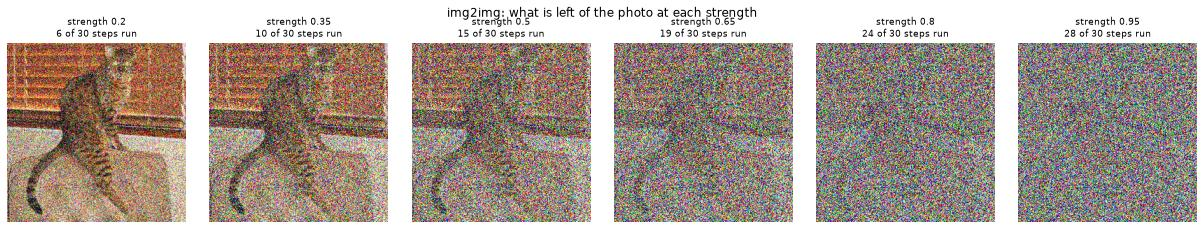

In [76]:
strengths = [0.2, 0.35, 0.5, 0.65, 0.8, 0.95]
fig, axes = plt.subplots(1, len(strengths), figsize=(17, 3.2))
for ax, s in zip(axes, strengths):
    t = int(s * (T_STEPS - 1))
    xt = np.sqrt(alpha_bar[t]) * x0 + np.sqrt(1 - alpha_bar[t]) * noise
    ax.imshow(((xt + 1) / 2).clip(0, 1))
    ax.set_title(f"strength {s}\n{int(30 * s)} of 30 steps run", fontsize=9)
    ax.axis("off")
fig.suptitle("img2img: what is left of the photo at each strength")
fig.tight_layout()
plt.show()

**IP-Adapter (`--ip-adapter-scale` λ).** The photo is not a starting point but a **second prompt**. A CLIP *image* encoder turns it into an embedding, and IP-Adapter adds extra cross-attention layers to the U-Net that attend to that embedding, next to the text cross-attention ("decoupled cross-attention"):

$$\text{out} = \text{Attn}(Q, K_{\text{text}}, V_{\text{text}}) + \lambda\,\text{Attn}(Q, K_{\text{img}}, V_{\text{img}})$$

Generation still starts from pure noise, so pose, framing and background are free, while the cat's appearance is pulled towards the photo. λ = 0 is plain t2i; λ = 1 is dominated by the image. CLIP embeddings are semantic rather than pixel-exact, so the *kind* of cat is transferred more reliably than its exact spot pattern.

The two modes keep different things: img2img keeps the photo's **layout**, IP-Adapter keeps its **content**. Comparing them tells which the classifier benefits from.

### 5.5 Meeting 4: inpainting and outpainting

**What it is meant to test:** *does the classifier need new cats or new backgrounds?* Both modes keep the real cat's pixels and change only its surroundings, using **SD 1.5 Inpainting**, a U-Net variant with extra input channels for the mask and the masked image, trained to fill holes consistently with their context.

- **Inpainting:** mask = everything the trimap doesn't mark as pet (section 2.7). The prompt describes the whole scene (cat and surroundings, several `--prompt`s cycle). After generation, `keep_cat()` pastes the original cat back with a softly blurred edge.
- **Outpainting (`--outpaint-scale` k):** the photo is shrunk by $k$ into the centre of a grey 512×512 canvas, the border is masked (with an 8 px overlap for blending), the model paints the frame, and the photo is pasted back. The camera steps back: same cat, smaller, more scene.

If the classifier was partly recognising *contexts* (sofas, lawns, lighting) rather than cats, new backgrounds around the same 15 cats should help; if it was short of cat appearances, they should not. Things to check on contact sheets: seams or halos at the fur edge, lighting mismatch between cat and scene, a second cat painted in, and how small the cat becomes after the classifier's 224 crop at large scales.

### 5.6 From pool to run

In [77]:
pd.DataFrame([
    ("t2i", "2", "SD 1.5 / SDXL-Turbo", "pure noise", "prompt", "--guidance, --steps, --scheduler, --model, --prompt"),
    ("img2img", "3", "SD 1.5", "noised training photo", "prompt + photo layout", "--strength"),
    ("ip-adapter", "3", "SD 1.5 + IP-Adapter", "pure noise", "prompt + CLIP image embedding", "--ip-adapter-scale"),
    ("inpaint", "4", "SD 1.5 Inpainting", "photo, background masked", "prompt (scene); real cat pasted back", "--prompt (scenes)"),
    ("outpaint", "4", "SD 1.5 Inpainting", "shrunk photo on grey canvas", "prompt; real photo pasted back", "--outpaint-scale"),
], columns=["mode", "meeting", "model", "starts from", "conditioned on", "main knob"]).set_index("mode")

,meeting,model,starts from,conditioned on,main knob
mode,,,,,
t2i,2,SD 1.5 / SDXL-Turbo,pure noise,prompt,"--guidance, --steps, --scheduler, --model, --p..."
img2img,3,SD 1.5,noised training photo,prompt + photo layout,--strength
ip-adapter,3,SD 1.5 + IP-Adapter,pure noise,prompt + CLIP image embedding,--ip-adapter-scale
inpaint,4,SD 1.5 Inpainting,"photo, background masked",prompt (scene); real cat pasted back,--prompt (scenes)
outpaint,4,SD 1.5 Inpainting,shrunk photo on grey canvas,prompt; real photo pasted back,--outpaint-scale


`synth-generate` writes a **pool** (`pools/NAME/`): the images, a `manifest.jsonl` line per attempt (prompt, seed, source photo, settings, status such as `ok` or `safety_blocked`), `pool.json`, and a `contact-sheet.jpg` of the first 24. The default pool has 110 images, twice the budget, so each seed draws a different 55.

`synth-train --method synthetic --pool NAME` draws 55 usable images per seed with `pools.draw()`: grouped by source photo, shuffled with the seed, taken round-robin across sources. In the photo-based modes every training photo is therefore represented about equally (3–4 images each), like oversampling, and "which source photo" does not become a confound. The 15 real Maus stay in the training set once each; the 55 synthetic images take the place of the 55 copies, so a synthetic run is directly comparable to `m1-oversample` and `m1-augment`.

In [78]:
fake = [{"sample_id": i, "source": mau_train[i % len(mau_train)]} for i in range(110)]
drawn = pools.draw(fake, config.BUDGET, random.Random(0))
per_source = pd.Series(Counter(r["source"].replace("Egyptian_Mau_", "#") for r in drawn)).sort_index()
print(f"{len(drawn)} images drawn for seed 0, per source photo:")
print(per_source.to_dict())

55 images drawn for seed 0, per source photo:
{'#104': 4, '#117': 4, '#119': 4, '#121': 4, '#123': 4, '#124': 4, '#134': 3, '#144': 4, '#147': 3, '#153': 4, '#154': 3, '#160': 3, '#165': 4, '#190': 4, '#192': 3}


## 6. Open questions to carry into the meetings

Things the exploration above makes worth checking in each meeting.

**About the data**
- The validation Maus that sit closest to another breed's prototype (2.6): do they stay wrong under every method, or does some method fix them? If they stay wrong, is it the photo (unusual coat, framing) or the breed boundary?
- Is the pet-share / framing distribution of the 15 training photos representative of val and test (2.2)? If not, which methods can change framing (outpainting, img2img at high strength, t2i) and does that show up?
- Do the breed-centroid similarities from the frozen backbone (2.6) match the confusion matrices of the fine-tuned models in Meeting 1? Where they differ, fine-tuning has moved a boundary.

**About the methods**
- Meeting 2: how often does the model draw a Mau rather than a generic spotted cat, and does that rate change with guidance or model? Is there a visible "AI look" that a classifier could latch on to?
- Meeting 3: where along the strength axis do images stop being copies and start being different cats? Does IP-Adapter preserve the spot pattern or only the silver colour?
- Meeting 4: do inpainted images look like real photos at the fur edge, and does the classifier's per-breed confusion change at all when only backgrounds change?
- Across meetings: whenever Mau recall rises, does Bengal recall fall? The confusion matrix answers whether a gain is real.

**What I expect across the course** (written before any training or generation):
- The prior, not the look of the breed, is the first problem: balancing alone (Meeting 1) should give the largest single jump in Mau recall, and later methods will be fighting for much smaller gains on top of it.
- Text-to-image (Meeting 2) is the riskiest: the backbone already places Mau next to Bengal, and a diffusion model asked for an "Egyptian Mau" may well draw a generic spotted cat. Images like that could push more Bengals to "Mau" without helping the real Maus.
- Photo-based methods (Meeting 3) should be safer but closer to oversampling: the lower the img2img strength, the more a pool behaves like copies of the 15 photos.
- New backgrounds (Meeting 4) should help less than new cats: the hard validation Maus are hard because of the cat's view and coat (close-ups, bronze, curled up), not because of the scene.
- The ones to watch in every meeting: the hardest validation Maus of 2.6, and Bengal recall.

**Rules that shape every answer** (README): one setting at a time, budget 55, only the 15 training photos as sources, choose on validation and write the choice down before testing, never revise after a test result, describe bad pools instead of deleting them.

### Glossary

| Term | Meaning |
| --- | --- |
| budget | the 55 extra Egyptian Mau training examples every method adds |
| pool | a folder of generated images with a manifest, made by `synth-generate` |
| run | 5 trained models (seeds 0–4) for one method or pool, in `runs/NAME/` |
| Mau recall | share of real Mau photos predicted as Mau |
| macro-F1 | unweighted mean of the 8 per-breed F1 scores |
| class prior | the model's learned tendency to predict frequent classes |
| domain gap | systematic difference between generated and real photos that a classifier can pick up |
| CFG / guidance | amplifying the difference between prompted and unprompted noise predictions |
| strength (img2img) | how far the photo is noised before denoising (0 = copy, 1 = new image) |
| IP-Adapter scale | weight of the image-prompt cross-attention |
| trimap | Oxford-IIIT Pet's per-pixel pet / background / border annotation |